# Projeto de Previsão Econômica com Agente Assistivo 
**Este projeto tem como objetivo desenvolver um sistema estruturado de coleta, tratamento e modelagem de dados macroeconômicos brasileiros, com foco na projeção do IPCA (inflação) e da taxa SELIC (juros básicos) até o ano de 2030.**

**A proposta integra técnicas de econometria de séries temporais (ARIMA e SARIMA) para estimar a dinâmica dessas variáveis, considerando persistência, possíveis tendências e sazonalidade.**

**O sistema contempla:**

- *Organização e consolidação das séries históricas*
- *Testes de estacionariedade*
- *Seleção automática de modelos via critérios de informação (AIC/BIC)*
- *Geração de projeções mensais*
- *Construção de cenários (base, pessimista e otimista)*

*Como diferencial, o projeto incorpora um agente assistivo capaz de interpretar os resultados econométricos e apoiar a análise dos cenários projetados, ampliando a utilidade do modelo para fins acadêmicos e analíticos.*

*O resultado é uma estrutura completa de previsão macroeconômica aplicada ao contexto brasileiro, combinando rigor estatístico, coerência econômica e suporte interpretativo.*

## Importações

In [1]:
import requests
import datetime
import nbformat
import numpy as np
import pandas as pd
import itertools
import matplotlib.pyplot as plt
from scipy import stats
from threading import Thread   
from scipy.stats import zscore
from flask import Flask, jsonify, request
from statsmodels.tsa.stattools import adfuller 
from sklearn.linear_model import LinearRegression
from statsmodels.tsa.statespace.sarimax import SARIMAX 
from nbconvert.preprocessors import ExecutePreprocessor

## Chamada da API

In [8]:
# chamada do caderno api_extracao.ipynb
%run api_extracao.ipynb

API de indicadores rodando! Acesse http://127.0.0.1:5000/indicadores
API rodando em:
http://127.0.0.1:5000/indicadores
 * Serving Flask app 'api_extracao'
 * Debug mode: off


 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://192.168.15.11:5000
Press CTRL+C to quit


Status code: 200


## Chamada do MODELO SARIMA IPCA

In [10]:
# chamada do modelo_sarima_ipca.ipynb
%run modelo_sarima_ipca.ipynb

## Chamada do MODELO ARIMA SELIC

In [11]:
# chamada do modelo_arima_selic.ipynb
%run modelo_arima_selic.ipynb

## Chamada da Tranformação dos dados

Estatística ADF: -6.736857889163577
p-valor: 3.191303096229373e-09
Conclusão: Série estacionária (rejeita H0)
Melhor modelo encontrado:
SARIMA(1, 0, 0, 0, 1, 1, 12)
AIC: 88.5447374748673

Resumo do modelo:
                                      SARIMAX Results                                       
Dep. Variable:                                valor   No. Observations:                  121
Model:             SARIMAX(1, 0, 0)x(0, 1, [1], 12)   Log Likelihood                 -41.272
Date:                              Sun, 08 Mar 2026   AIC                             88.545
Time:                                      15:36:01   BIC                             96.238
Sample:                                  01-01-2016   HQIC                            91.654
                                       - 01-01-2026                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P

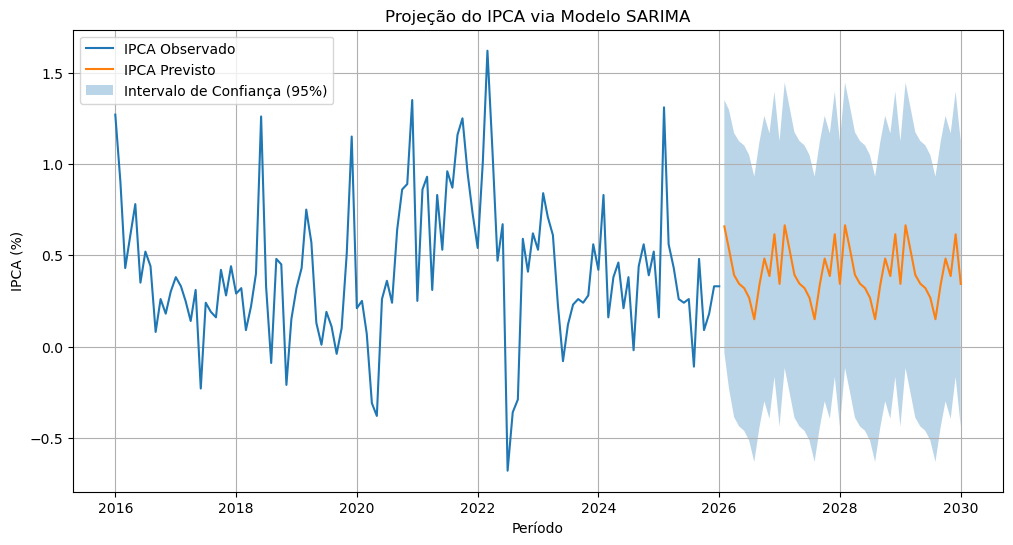

Tipo de regressão: c
Estatística ADF: -2.6569735469638287
p-valor: 0.0817842025620713
Lags utilizados: 3
Número de observações: 119
Conclusão: Não se rejeita H0 → Série não estacionária
Melhor modelo encontrado:
ARIMA(2, 1, 1)
AIC: -1250.1765476086434

Resumo do modelo:
                               SARIMAX Results                                
Dep. Variable:                  valor   No. Observations:                  123
Model:               SARIMAX(2, 1, 1)   Log Likelihood                 629.088
Date:                Sun, 08 Mar 2026   AIC                          -1250.177
Time:                        15:36:04   BIC                          -1239.027
Sample:                    01-01-2016   HQIC                         -1245.648
                         - 03-01-2026                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------

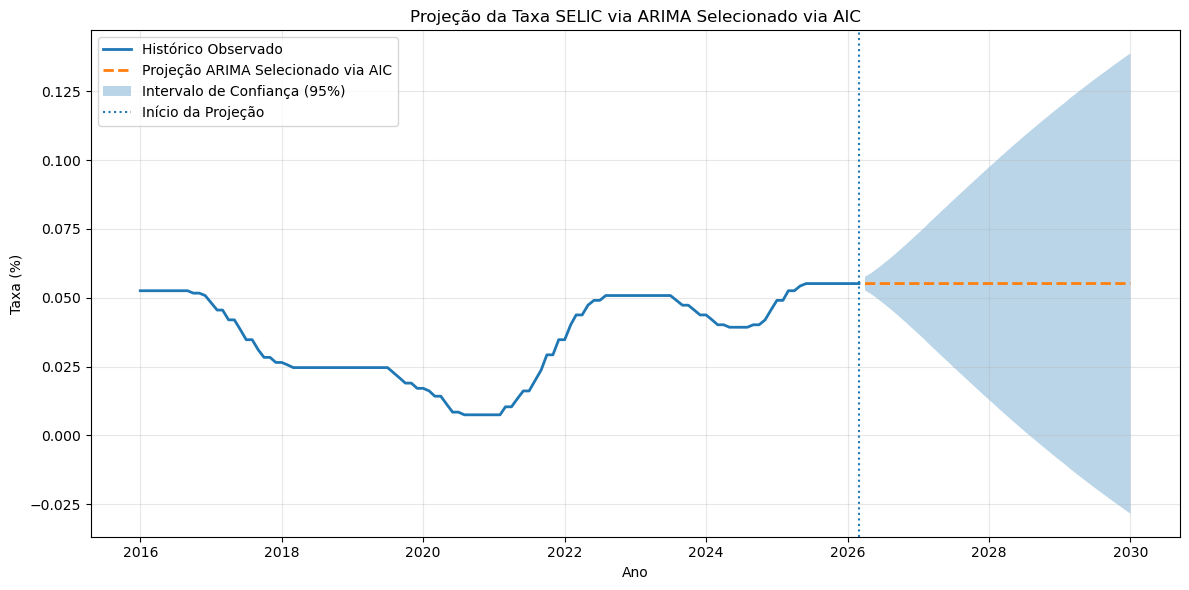

In [15]:
# chamada do caderno feature_engineering.ipynb
%run feature_engineering.ipynb

## Chamada dos Cálculos Financeiros BACEN

In [82]:
%run macro_indicadores_processados.ipynb

## Chamada do agente assistivo

In [ ]:
%run agente_assistivo.ipynb

In [111]:
df = df_iqr

In [110]:
df = df_iqr

df_filtrado = df[
    (df['data'] >= '2027-01-01') &
    (df['data'] <= '2027-02-01')
]
df_filtrado

,data,periodo_cenario,cenarios,IPCA,SELIC,juros_real,vol_jrs_real_cnr,vol_jrs_real_cnr_ano,vol_juros_real_12m,IPCA_acum_12m,...,corr_IPCA_juros_real_12m,Z_IPCA_acum_12m_12m,Z_SELIC_acum_12m_12m,Z_juros_real_12m,IQR_IPCA_acum_12m_12m,outlier_IPCA_acum_12m_12m,IQR_SELIC_acum_12m_12m,outlier_SELIC_acum_12m_12m,IQR_juros_real_12m,outlier_juros_real_12m
134,2027-01-01,projetado,base,0.003430,0.055140,0.051533,0.016257,0.001541,0.001530,0.049326,...,0.188696,0.810657,0.421350,0.406466,0.006394,False,0.000053,False,0.001699,False
135,2027-02-01,projetado,base,0.006642,0.055141,0.048179,0.016257,0.001541,0.001539,0.049390,...,-0.293280,0.724698,1.814015,-1.773426,0.004696,False,0.000061,False,0.001699,False
304,2027-01-01,projetado,otimista,0.011246,0.073384,0.061447,0.030093,0.007417,0.006352,0.150372,...,0.972034,1.294966,1.975156,1.638110,0.054075,False,0.089539,False,0.008171,False
305,2027-02-01,projetado,otimista,0.014458,0.075379,0.060052,0.030093,0.007417,0.005999,0.151462,...,0.967914,1.163523,1.930652,1.238619,0.051399,False,0.108744,False,0.008320,False
474,2027-01-01,projetado,pessimista,-0.004386,0.036896,0.041465,0.020260,0.007298,0.006106,-0.043524,...,0.941415,-1.411525,-1.934570,-1.525391,0.036406,False,0.085296,False,0.009977,False
475,2027-02-01,projetado,pessimista,-0.001174,0.034903,0.036119,0.020260,0.007298,0.007209,-0.044327,...,0.953812,-1.250291,-1.876365,-1.809677,0.038461,False,0.101838,False,0.010939,False


In [134]:
class MacroAgent:

    def __init__(self, df):
        """
        Dataframe contem:

        datas 
        cenarios
        periodo_cenario

        séries econômicas:
        IPCA
        SELIC
        juros_real

        acumulados:
        IPCA_acum_12m
        SELIC_acum_12m

        métricas:
        volatilidade
        correlação rolante
        Z-score
        IQR
        outliers
        """

        self.df = df_iqr.copy()
        self.df['data'] = pd.to_datetime(self.df['data'])

        self.validation_report = {}
        self.trend_report = {}
        self.correlation_report = {}
        self.alert_report = []

    # VALIDAÇÃO DOS DADOS
    def validate(self):

        df = self.df

        # valores faltantes
        missing = df.isna().sum()

        # contagem de outliers
        outliers_ipca = df["outlier_IPCA_acum_12m_12m"].sum()
        outliers_selic = df["outlier_SELIC_acum_12m_12m"].sum()
        outliers_jr = df["outlier_juros_real_12m"].sum()

        # z-score extremos
        z_ipca = (df["Z_IPCA_acum_12m_12m"].abs() > 2).sum()
        z_selic = (df["Z_SELIC_acum_12m_12m"].abs() > 2).sum()
        z_jr = (df["Z_juros_real_12m"].abs() > 2).sum()

        self.validation_report = {

            "missing_values": missing.to_dict(),

            "outliers": {
                "ipca": int(outliers_ipca),
                "selic": int(outliers_selic),
                "juros_real": int(outliers_jr)
            },

            "zscore_extremos": {
                "ipca": int(z_ipca),
                "selic": int(z_selic),
                "juros_real": int(z_jr)
            }
        }

    # TENDÊNCIAS MACROECONÔMICAS
    def analyze_trends(self):

        df = self.df

        for cenario in df["cenarios"].unique():

            df_c = df[df["cenarios"] == cenario]

            ipca_trend = df_c["tendencia_IPCA_12m_anual"].iloc[0]
            selic_trend = df_c["tendencia_SELIC_12m_anual"].iloc[0]

            vol_jr = df_c["vol_juros_real_12m"].mean()

            self.trend_report[cenario] = {

                "tendencia_ipca_anual": ipca_trend,
                "tendencia_selic_anual": selic_trend,
                "volatilidade_juros_real": vol_jr

            }

    # CORRELAÇÃO MONETÁRIA
    def analyze_correlation(self):

        df = self.df

        for cenario in df["cenarios"].unique():

            df_c = df[df["cenarios"] == cenario]

            corr_ipca_selic = df_c["corr_IPCA_SELIC_acum_12m"].mean()
            corr_ipca_jr = df_c["corr_IPCA_juros_real_12m"].mean()

            self.correlation_report[cenario] = {

                "corr_ipca_selic": corr_ipca_selic,
                "corr_ipca_juros_real": corr_ipca_jr
            }

    # DETECÇÃO DE ALERTAS
    def generate_alerts(self):

        df = self.df

        for col in ["Z_IPCA_acum_12m_12m","Z_SELIC_acum_12m_12m","Z_juros_real_12m"]:

            qtd = (df[col].abs() > 2).sum()

            if qtd > 0:

                self.alert_report.append({
                    "tipo":"zscore_extremo",
                    "indicador":col,
                    "quantidade":int(qtd)
                })


        for col in ["outlier_IPCA_acum_12m_12m","outlier_SELIC_acum_12m_12m","outlier_juros_real_12m"]:

            qtd = df[col].sum()

            if qtd > 0:

                self.alert_report.append({
                    "tipo":"outlier_IQR",
                    "indicador":col,
                    "quantidade":int(qtd)
                })

    # INTERPRETAÇÃO ECONÔMICA
    def interpret_results(self):

        insights = []

        for cenario in self.trend_report:

            trend = self.trend_report[cenario]
            corr = self.correlation_report[cenario]

            ipca = trend["tendencia_ipca_anual"]
            selic = trend["tendencia_selic_anual"]
            vol = trend["volatilidade_juros_real"]

            corr_ipca_selic = corr["corr_ipca_selic"]

            # interpretação inflação
            if ipca > 0:
                inflacao_msg = "trajetória inflacionária ascendente"
            elif ipca < 0:
                inflacao_msg = "trajetória de desaceleração inflacionária"
            else:
                inflacao_msg = "estabilidade inflacionária"

            # política monetária
            if corr_ipca_selic > 0.7:
                politica = "política monetária reage fortemente à inflação"
            elif corr_ipca_selic > 0.3:
                politica = "política monetária parcialmente alinhada com a inflação"
            elif corr_ipca_selic < 0:
                politica = "possível descompasso entre inflação e política monetária"
            else:
                politica = "relação fraca entre inflação e juros"

            # volatilidade
            if vol < 0.002:
                risco = "ambiente macroeconômico estável"
            elif vol < 0.005:
                risco = "volatilidade moderada"
            else:
                risco = "ambiente macroeconômico instável"

            texto = f"""
CENÁRIO {cenario.upper()}

Dinâmica inflacionária:
O IPCA apresenta {inflacao_msg}, com tendência anual estimada de {ipca:.4f}.

Política monetária:
A SELIC apresenta tendência anual de {selic:.4f}.
A correlação média entre inflação e juros é {corr_ipca_selic:.2f}, indicando que {politica}.

Estabilidade macroeconômica:
A volatilidade média do juros real é {vol:.4f}, sugerindo {risco}.
"""

            insights.append(texto)

        # alertas
        if self.alert_report:

            insights.append("\nRISCOS MACROECONÔMICOS DETECTADOS:")

            for alerta in self.alert_report:

                if alerta["tipo"] == "zscore_extremo":

                    insights.append(
                        f"- Desvios estatísticos detectados no indicador {alerta['indicador']} ({alerta['quantidade']} observações)."
                    )

                if alerta["tipo"] == "outlier_IQR":

                    insights.append(
                        f"- Outliers detectados via IQR no indicador {alerta['indicador']} ({alerta['quantidade']} ocorrências)."
                    )

        return "\n".join(insights)

    # VISUALIZAÇÕES
    def visualize(self):

        df = self.df

        for cenario in df["cenarios"].unique():

            df_c = df[df["cenarios"] == cenario]

            plt.figure()

            plt.plot(df_c["data"], df_c["IPCA_acum_12m"], label="IPCA 12m")
            plt.plot(df_c["data"], df_c["SELIC_acum_12m"], label="SELIC 12m")

            plt.title(f"Tendência Macro - {cenario}")
            plt.legend()

            plt.show()
            
    # RELATÓRIO FINAL
    def generate_report(self):

        self.validate()

        self.analyze_trends()

        self.analyze_correlation()

        self.generate_alerts()

        return self.interpret_results()

    # DASHBOARD MACRO
    def plot_macro_dashboard(self):

        df = self.df

        for cenario in df["cenarios"].unique():

            df_c = df[df["cenarios"] == cenario]

            fig, axes = plt.subplots(4, 1, figsize=(14, 16), sharex=True)

            # Inflação vs Política Monetária
            axes[0].plot(
                df_c["data"],
                df_c["IPCA_acum_12m"],
                label="Inflação IPCA (12 meses)",
                color="red",
                linewidth=2
            )

            axes[0].plot(
                df_c["data"],
                df_c["SELIC_acum_12m"],
                label="Taxa SELIC (12 meses)",
                color="blue",
                linewidth=2
            )

            axes[0].set_title(
                "Inflação vs Política Monetária",
                fontsize=13,
                fontweight="bold"
            )

            axes[0].set_ylabel("Taxa (%)")

            axes[0].legend(loc="upper left")

            axes[0].grid(True, alpha=0.3)

            axes[0].text(
                0.01,
                0.92,
                "Comparação entre inflação acumulada e taxa básica de juros.\nIndica reação da política monetária à inflação.",
                transform=axes[0].transAxes,
                fontsize=9
            )

        # Juros Real
            axes[1].plot(
                df_c["data"],
                df_c["juros_real"],
                color="green",
                linewidth=2,
                label="Juros Real"
            )

            axes[1].axhline(0, linestyle="--", color="black")

            axes[1].set_title(
                "Juros Real da Economia",
                fontsize=13,
                fontweight="bold"
            )

            axes[1].set_ylabel("Taxa (%)")

            axes[1].legend()

            axes[1].grid(True, alpha=0.3)

            axes[1].text(
                0.01,
                0.9,
                "Juros real = SELIC - inflação.\nValores negativos indicam política monetária expansionista.",
                transform=axes[1].transAxes,
                fontsize=9
            )

        # Correlação Inflação x Juros
            axes[2].plot(
                df_c["data"],
                df_c["corr_IPCA_SELIC_acum_12m"],
                color="purple",
                linewidth=2
            )

            axes[2].axhline(0, linestyle="--", color="black")

            axes[2].axhline(0.7, linestyle=":", color="gray")

            axes[2].set_title(
                "Correlação entre Inflação e Política Monetária",
                fontsize=13,
                fontweight="bold"
            )

            axes[2].set_ylabel("Correlação")

            axes[2].grid(True, alpha=0.3)

            axes[2].text(
                0.01,
                0.9,
                "Correlação alta sugere forte reação do Banco Central à inflação.",
                transform=axes[2].transAxes,
                fontsize=9
            )

            # Stress Macroeconômico
            axes[3].plot(
                df_c["data"],
                df_c["Z_IPCA_acum_12m_12m"],
                label="Z-score Inflação",
                color="red"
            )

            axes[3].plot(
                df_c["data"],
                df_c["Z_SELIC_acum_12m_12m"],
                label="Z-score Juros",
                color="blue"
            )
    
            axes[3].axhline(2, linestyle="--", color="darkred")
            axes[3].axhline(-2, linestyle="--", color="darkred")
    
            axes[3].set_title(
                "Indicador de Stress Macroeconômico (Z-score)",
                fontsize=13,
                fontweight="bold"
            )
    
            axes[3].set_ylabel("Desvio padrão")
    
            axes[3].legend()
    
            axes[3].grid(True, alpha=0.3)
    
            axes[3].text(
                0.01,
                0.9,
                "Valores acima de ±2 indicam choques macroeconômicos relevantes.",
                transform=axes[3].transAxes,
                fontsize=9
            )
            
            # Título geral
            plt.suptitle(
                f"Dashboard Macroeconômico — Cenário {cenario}",
                fontsize=16,
                fontweight="bold"
            )
    
            plt.tight_layout()
    
            plt.show()


CENÁRIO BASE

Dinâmica inflacionária:
O IPCA apresenta trajetória inflacionária ascendente, com tendência anual estimada de 0.0007.

Política monetária:
A SELIC apresenta tendência anual de 0.0470.
A correlação média entre inflação e juros é 0.03, indicando que relação fraca entre inflação e juros.

Estabilidade macroeconômica:
A volatilidade média do juros real é 0.0045, sugerindo volatilidade moderada.


CENÁRIO OTIMISTA

Dinâmica inflacionária:
O IPCA apresenta trajetória inflacionária ascendente, com tendência anual estimada de 0.0088.

Política monetária:
A SELIC apresenta tendência anual de 0.1387.
A correlação média entre inflação e juros é 0.17, indicando que relação fraca entre inflação e juros.

Estabilidade macroeconômica:
A volatilidade média do juros real é 0.0059, sugerindo ambiente macroeconômico instável.


CENÁRIO PESSIMISTA

Dinâmica inflacionária:
O IPCA apresenta trajetória de desaceleração inflacionária, com tendência anual estimada de -0.0067.

Política monetária

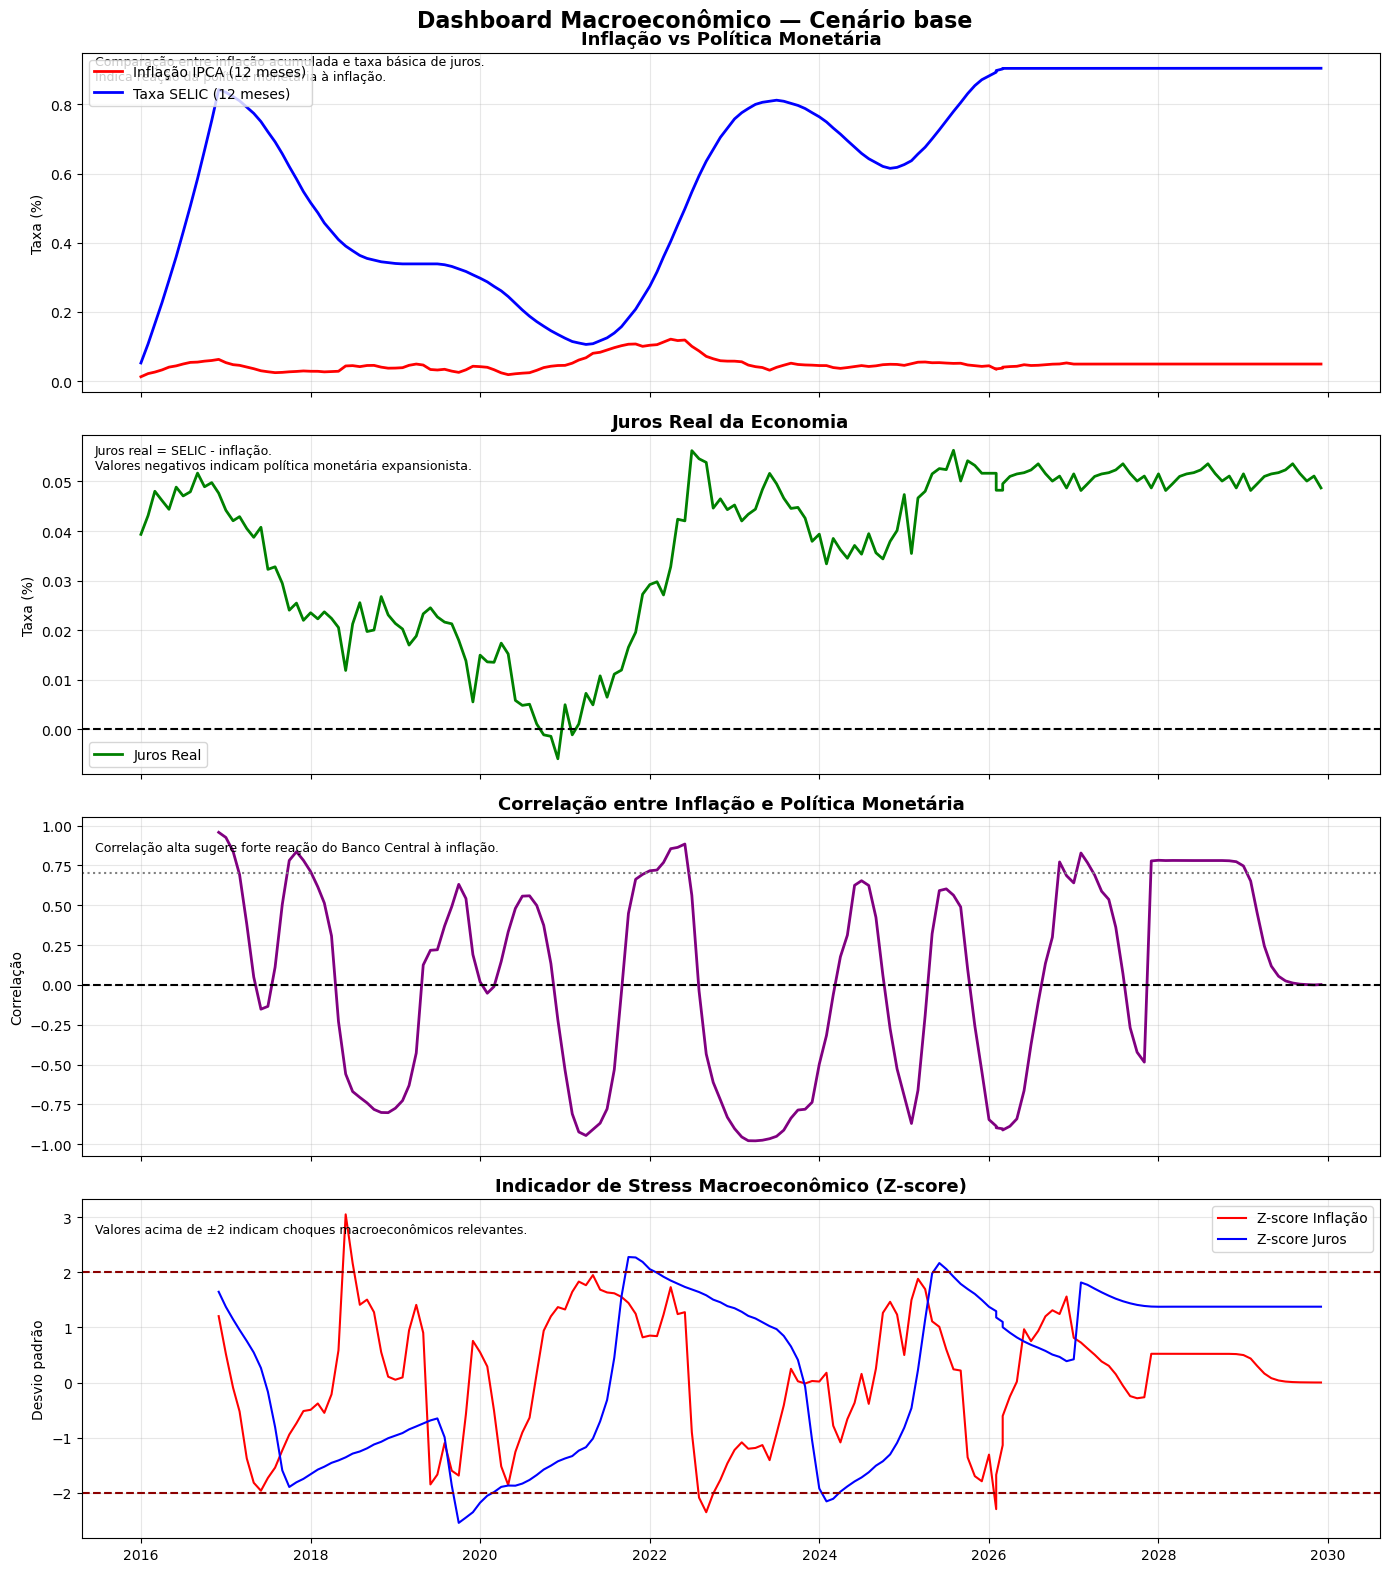

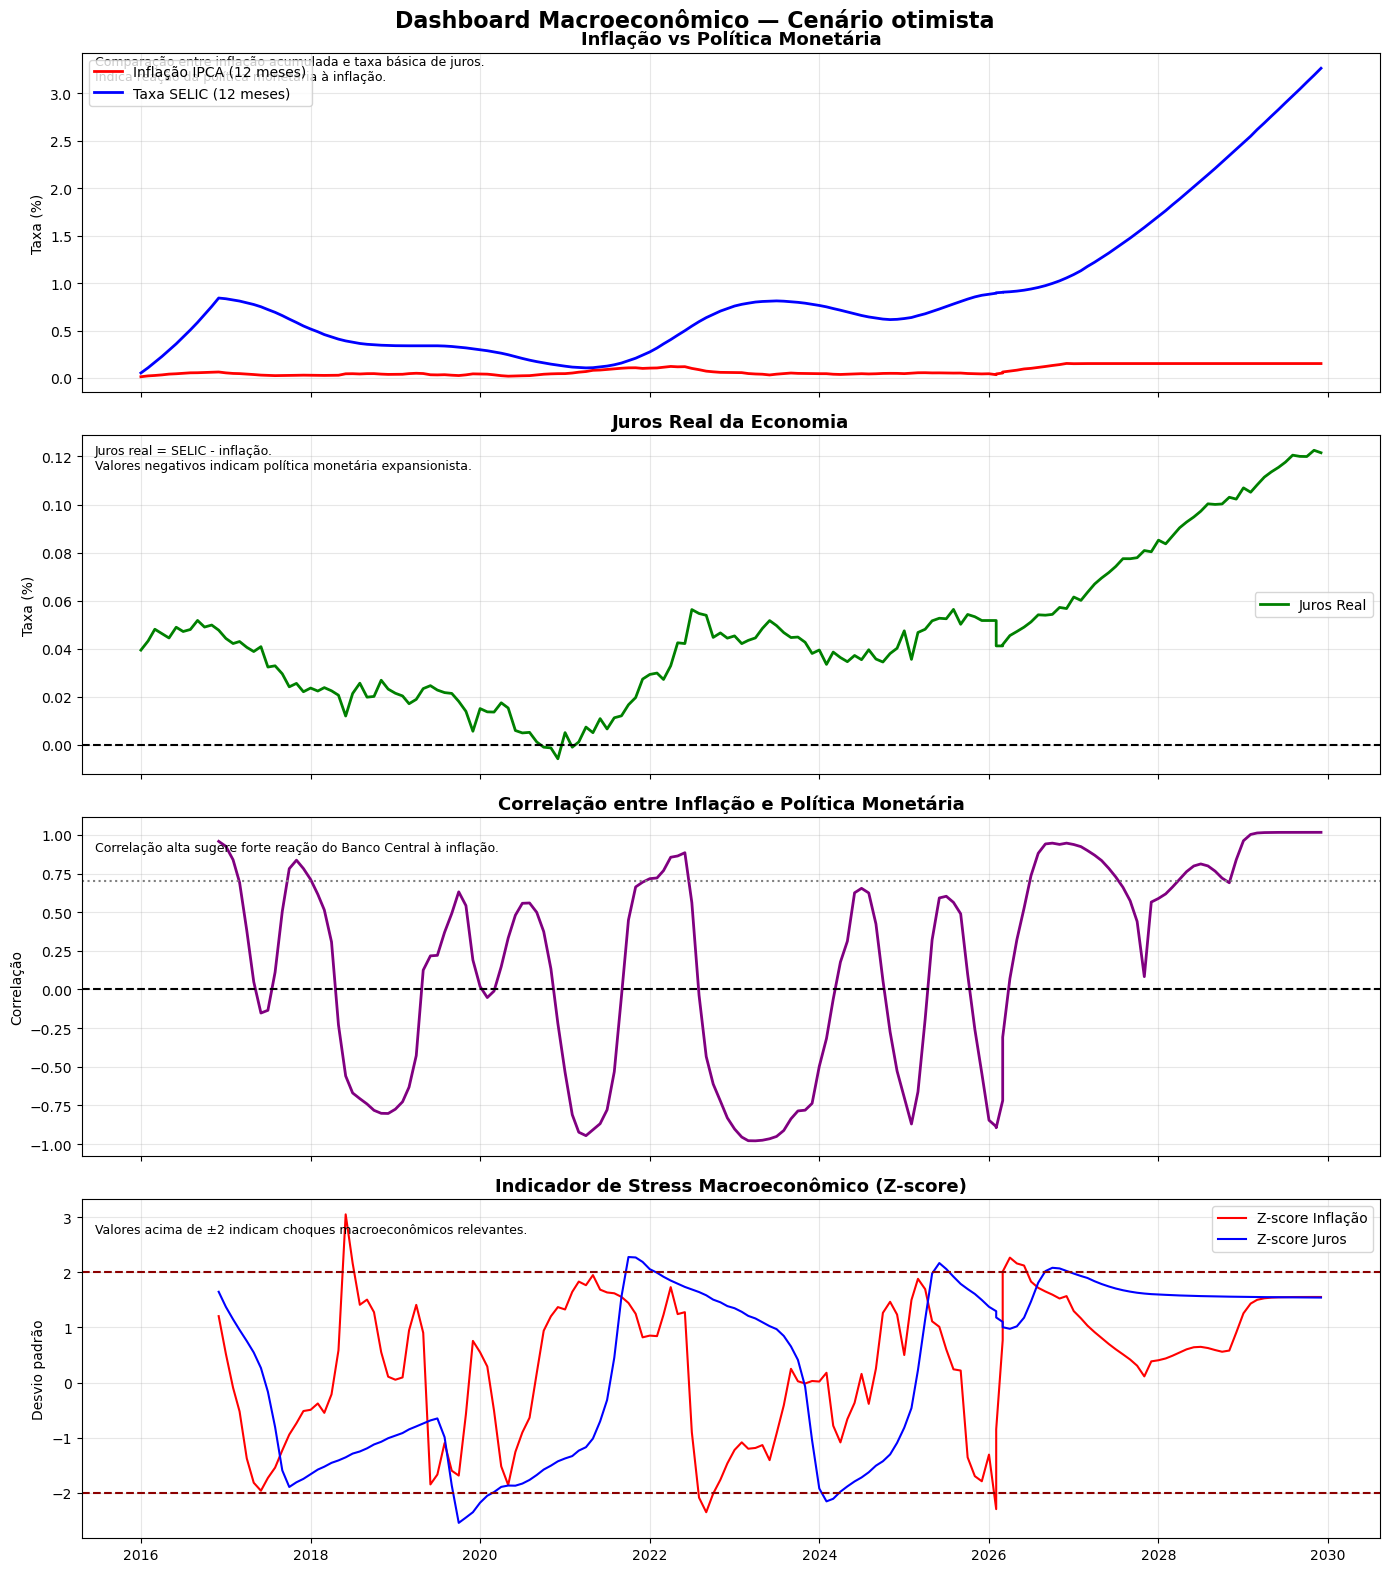

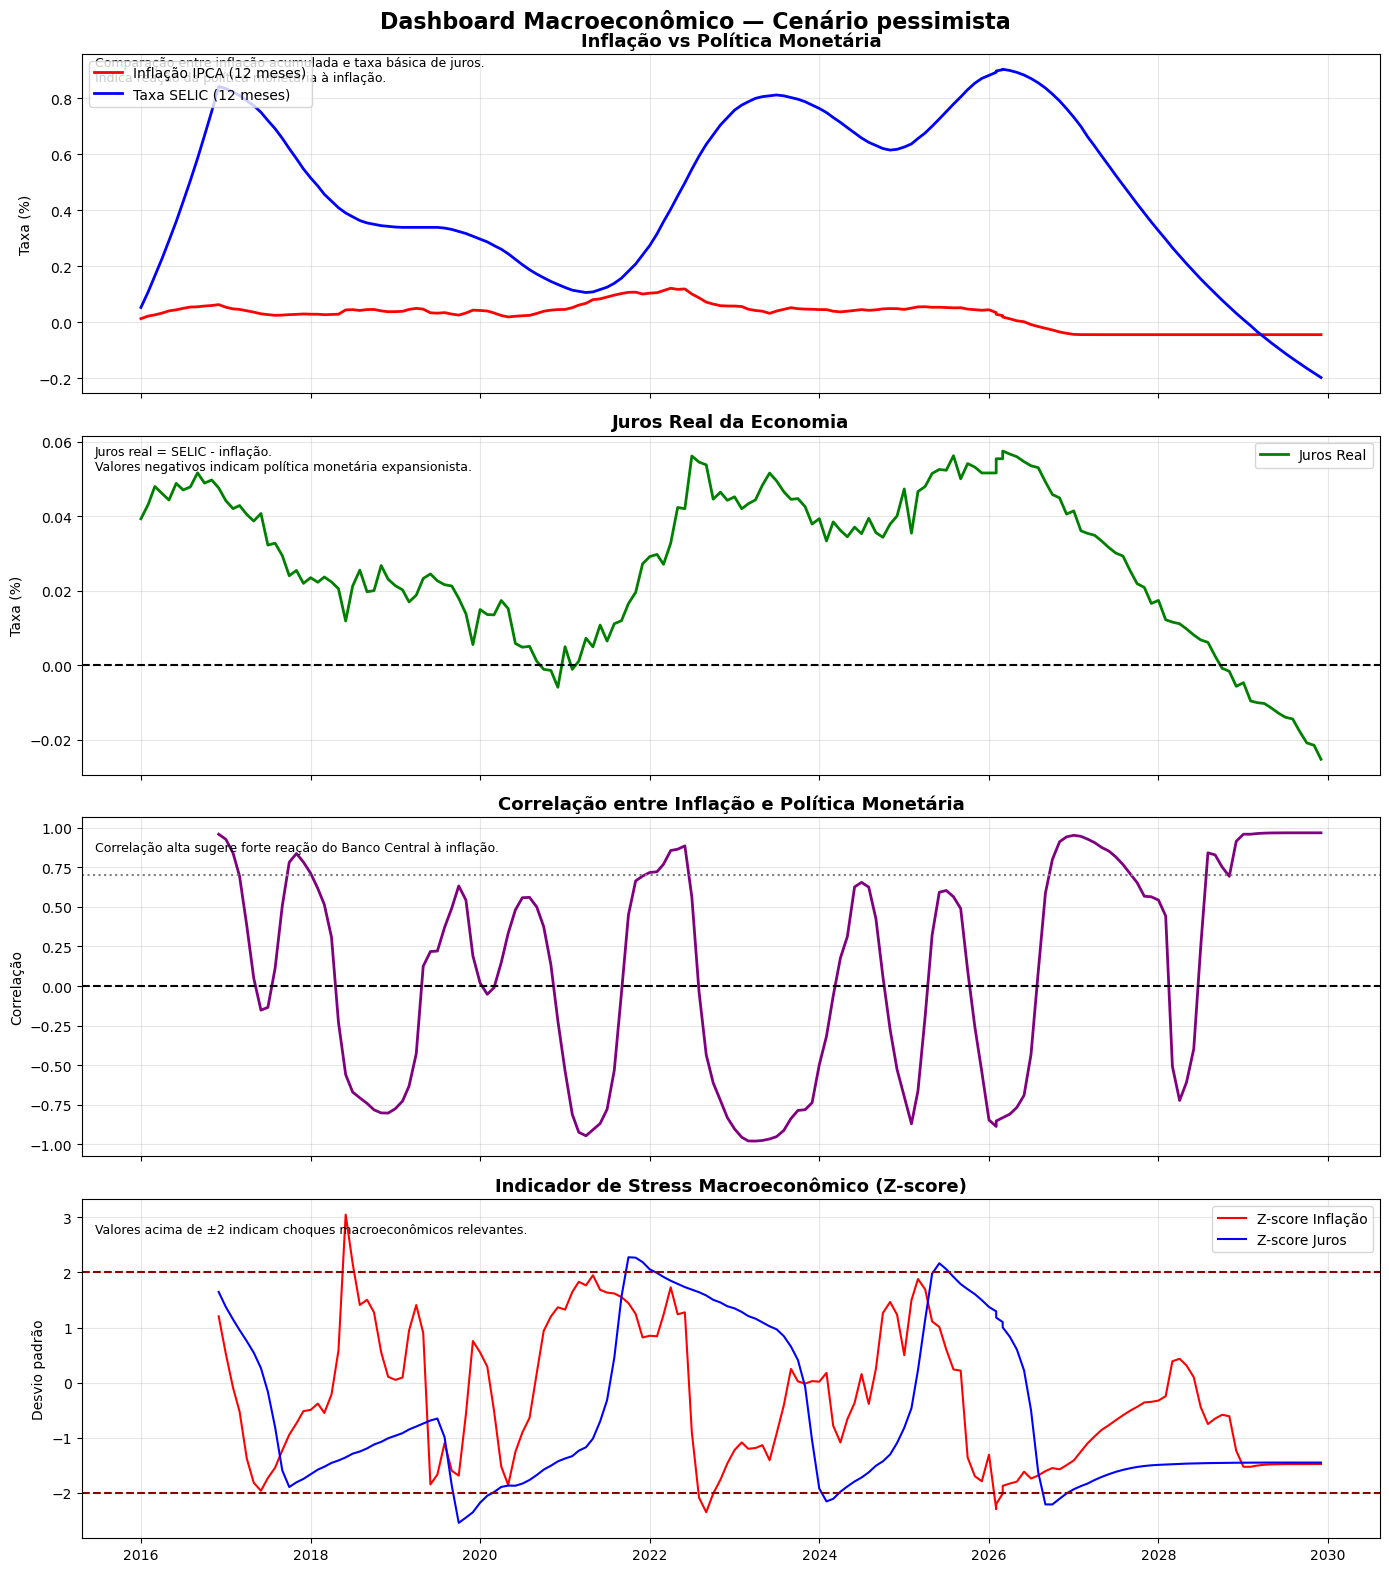

In [135]:
agent = MacroAgent(df)

relatorio = agent.generate_report()

print(relatorio)

agent.plot_macro_dashboard()


# Chamada do Relatorio Automatizado

In [ ]:
# chamada do caderno relatorio_automatizado.ipynb
%run relatorio_automatizado.ipynb

# Como o agente ajuda o cientista de dados?
Síntese automática de dados macroeconômicos

Em vez de analisar várias séries temporais manualmente, o agente transforma os dados em interpretação econômica automática.

Exemplo do relatório:

tendência da inflação

tendência da política monetária

relação entre inflação e juros

estabilidade macroeconômica

Isso reduz muito o tempo de análise exploratória.

📈 2️⃣ Análise de cenários econômicos

O agente compara três cenários macroeconômicos:

cenário base

cenário otimista

cenário pessimista

Isso ajuda cientistas de dados a:

testar hipóteses

avaliar riscos

simular políticas econômicas

Por exemplo:

Cenário Base

inflação subindo levemente

juros crescendo mais rápido

volatilidade moderada

Interpretação:

➡ política monetária está reagindo à inflação, mas de forma limitada.

🏦 3️⃣ Avaliação da política monetária

O agente mede a correlação entre inflação e juros.

No seu resultado:

correlação média entre inflação e juros = 0.03

Interpretação:

➡ relação muito fraca entre inflação e resposta da taxa de juros.

Isso pode indicar:

atraso na política monetária

baixa transmissão da política econômica

regime monetário instável

Esse tipo de análise é muito usado em:

bancos centrais

research de bancos

hedge funds macro

⚠️ 4️⃣ Detecção automática de risco macroeconômico

O agente também identifica anomalias estatísticas usando:

Z-score

outliers via IQR

No seu relatório foram detectados:

24 desvios extremos na inflação

47 desvios extremos na SELIC

28 desvios nos juros reais

Isso pode indicar:

choques inflacionários

mudanças bruscas na política monetária

instabilidade econômica

Esse tipo de análise é útil para monitoramento de risco macro.

📉 5️⃣ Medição de estabilidade econômica

O agente usa volatilidade do juros real para avaliar estabilidade.

Exemplo:

volatilidade média = 0.0045

Interpretação:

➡ ambiente macroeconômico moderadamente volátil.

Isso ajuda cientistas de dados a:

avaliar regimes econômicos

identificar períodos de crise

ajustar modelos preditivos